# 3. Grid numbering: streets relative to a compass direction

[`02_radial_numbering.ipynb`](02_radial_numbering.ipynb) covers towns
that grew outward from a center point. Many planned towns are laid out
on a regular grid instead, with no single meaningful center. Think of
Manhattan's avenues (numbered heading one way) and streets (numbered
heading the perpendicular way). Compass direction is the relevant idea
there, not distance to a point.

`assign_street_directionality(..., numbering_mode="grid")` implements
this. Instead of a center point, it takes a compass direction,
`direction_deg` (0° is north, measured clockwise, the default), plus
its perpendicular 90° clockwise from it (east, by default). These are
the grid's two numbering axes. It classifies each street as primary
(parallel to `direction_deg`) or cross (parallel to the perpendicular),
picks a numbering start, and walks the street the same way radial mode
does.

`origin` is accepted by the function for symmetry with radial mode,
but is ignored in grid mode. No center point is needed at all.

In [1]:
import matplotlib.pyplot as plt
from _tutorial_utils import (
    build_idealized_grid, label_and_direct_grid, make_graph, plot_grid_directionality,
)

plt.rcParams["figure.dpi"] = 110

## Example 1: a north/south street (default direction: north)

With the default `direction_deg=0` (north), a street running due
north/south has a bearing of 0°/180°, folded mod 180° to 0°. That
matches `direction_deg` exactly, closer than the perpendicular (90°).
It's classified primary.

Numbering starts at the southern end, the endpoint with the smaller
projection onto the north unit vector. The labeled length ranges below
climb heading north. That's the direction cumulative length increases.

,street_id,road_type,length_m
0,1,primary,50.0


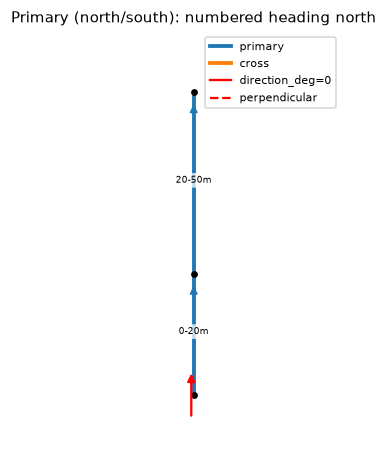

In [2]:
G = make_graph([
    (0, 1, (0, 10), (0, 30)),
    (1, 2, (0, 30), (0, 60)),
])
nodes_gdf, edges_gdf, streets_df = label_and_direct_grid(G, direction_deg=0.0)
display(streets_df[["street_id", "road_type", "length_m"]])
plot_grid_directionality(edges_gdf, nodes_gdf, streets_df, direction_deg=0.0,
                          title="Primary (north/south): numbered heading north")
plt.show()

## Example 2: an east/west street (default direction: north)

The perpendicular case. A street running due east/west has a bearing
90° from `direction_deg`, closer to the perpendicular axis. It's
classified cross.

Numbering starts at its western end, so cumulative length increases
heading east, 90° clockwise from `direction_deg`.

,street_id,road_type,length_m
0,1,cross,30.0


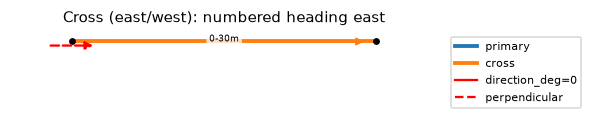

In [3]:
G = make_graph([
    (0, 1, (10, 0), (40, 0)),
])
nodes_gdf, edges_gdf, streets_df = label_and_direct_grid(G, direction_deg=0.0)
display(streets_df[["street_id", "road_type", "length_m"]])
plot_grid_directionality(edges_gdf, nodes_gdf, streets_df, direction_deg=0.0,
                          title="Cross (east/west): numbered heading east")
plt.show()

## Example 3: rotating `direction_deg`

The same east/west street as above, but now with `direction_deg=90`.
East is now the primary compass direction, north its perpendicular.
The street's own geometry hasn't changed. Only its classification has
flipped, from cross to primary, because it's now the axis closer to
`direction_deg`.

This is a genuine axis rotation, not a label swap. It's the tool for
aligning the numbering scheme with a town's own dominant street
orientation instead of assuming true north/south. Many real grids are
rotated relative to true north, following a coastline, a river, or old
property lines.

,street_id,road_type,length_m
0,1,primary,30.0


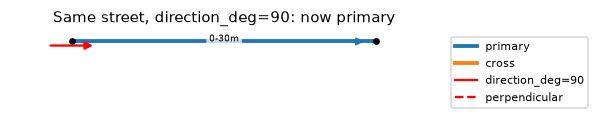

In [4]:
G = make_graph([
    (0, 1, (10, 0), (40, 0)),
])
nodes_gdf, edges_gdf, streets_df = label_and_direct_grid(G, direction_deg=90.0)
display(streets_df[["street_id", "road_type", "length_m"]])
plot_grid_directionality(edges_gdf, nodes_gdf, streets_df, direction_deg=90.0,
                          title="Same street, direction_deg=90: now primary")
plt.show()

## Putting it together: the idealized grid

Reusing the idealized grid builder (all residential, no named or
primary rows) with the default `direction_deg=0` (north). The grid's
rows run east/west and its columns run north/south. Unlike radial
mode, this classification doesn't depend on where any origin sits.
Every row comes out cross, numbered heading east. Every column comes
out primary, numbered heading north.

,street_id,road_type,length_m
0,1,cross,400.0
1,2,primary,400.0
2,3,primary,400.0
3,4,primary,400.0
4,5,primary,400.0
5,6,primary,400.0
6,7,cross,400.0
7,8,cross,400.0
8,9,cross,400.0
9,10,cross,400.0


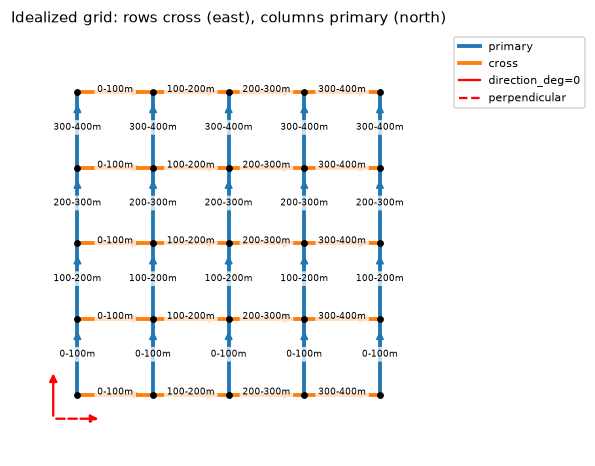

In [5]:
ROWS, COLS, SPACING = 5, 5, 100.0
G = build_idealized_grid(rows=ROWS, cols=COLS, spacing=SPACING, named_row=None, primary_row=None)

nodes_gdf, edges_gdf, streets_df = label_and_direct_grid(G, direction_deg=0.0)
display(streets_df[["street_id", "road_type", "length_m"]])
plot_grid_directionality(edges_gdf, nodes_gdf, streets_df, direction_deg=0.0,
                          title="Idealized grid: rows cross (east), columns primary (north)")
plt.show()

The labeled length ranges climb north for primary streets, east for
cross streets, with the default `direction_deg=0`. These are the same
`street_start_length_m`/`street_end_length_m` fields
`assign_street_directionality` adds regardless of `numbering_mode`.

Grid mode needs no center point at all, only a compass direction. It's
the better fit for a town laid out on a regular grid rather than one
that grew outward from a downtown.